<a href="https://colab.research.google.com/github/Raditya-Z/MachineLearning_244107020144/blob/main/QUIZ1/DBScan%20Revisi/PERBANDINGAN_DBSCAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Perbandingan Performa DBSCAN Berdasarkan Distance Metric

Notebook ini digunakan untuk membandingkan hasil clustering algoritma DBSCAN menggunakan tiga pendekatan jarak:

1. DBSCAN Cosine Distance
2. DBSCAN Euclidean Distance
3. DBSCAN Manhattan Distance

Data yang dibandingkan berasal dari hasil evaluasi masing-masing model DBSCAN.


## 0. Import Library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## 1. Memuat Hasil Evaluasi DBSCAN

Upload atau letakkan tiga file hasil evaluasi:
- evaluasi_dbscan_Cosine.xlsx
- evaluasi_dbscan_Euclidean.xlsx
- evaluasi_dbscan_Manhattan.xlsx

In [2]:
# Sesuaikan nama file jika berbeda

cosine = pd.read_excel("evaluasi_dbscan_Cosine.xlsx")
euclidean = pd.read_excel("evaluasi_dbscan_Euclidean.xlsx")
manhattan = pd.read_excel("evaluasi_dbscan_Manhattan.xlsx")

cosine["Metode"] = "Cosine"
euclidean["Metode"] = "Euclidean"
manhattan["Metode"] = "Manhattan"

hasil = pd.concat([cosine, euclidean, manhattan], ignore_index=True)

hasil


,Model,Distance Metric,eps,min_samples,Jumlah Cluster,Jumlah Noise,Noise (%),Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑),Execution Time (s) (↓),Alokasi Memori (MB),Metode
0,DBSCAN Cosine,Cosine Distance,0.3869,10,4,1114,22.28,0.1461,1.8416,398.42,0.54642,383.84,Cosine
1,DBSCAN Euclidean,Euclidean Distance (L2),4.5280,10,2,834,16.68,0.2049,1.5677,551.37,0.16069,3.25,Euclidean
2,DBSCAN Manhattan,Manhattan Distance (L1),16.9631,10,2,297,5.94,0.0931,1.5228,4.26,0.53976,3.45,Manhattan


## 2. Perbandingan Evaluasi Model DBSCAN

Evaluasi dilakukan berdasarkan:
- Silhouette Score (semakin tinggi semakin baik)
- Davies-Bouldin Index (semakin rendah semakin baik)
- Calinski-Harabasz Index (semakin tinggi semakin baik)
- Persentase Noise (semakin rendah semakin baik)


In [3]:
hasil


,Model,Distance Metric,eps,min_samples,Jumlah Cluster,Jumlah Noise,Noise (%),Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑),Execution Time (s) (↓),Alokasi Memori (MB),Metode
0,DBSCAN Cosine,Cosine Distance,0.3869,10,4,1114,22.28,0.1461,1.8416,398.42,0.54642,383.84,Cosine
1,DBSCAN Euclidean,Euclidean Distance (L2),4.5280,10,2,834,16.68,0.2049,1.5677,551.37,0.16069,3.25,Euclidean
2,DBSCAN Manhattan,Manhattan Distance (L1),16.9631,10,2,297,5.94,0.0931,1.5228,4.26,0.53976,3.45,Manhattan


## 2.1 Perbandingan Silhouette Score

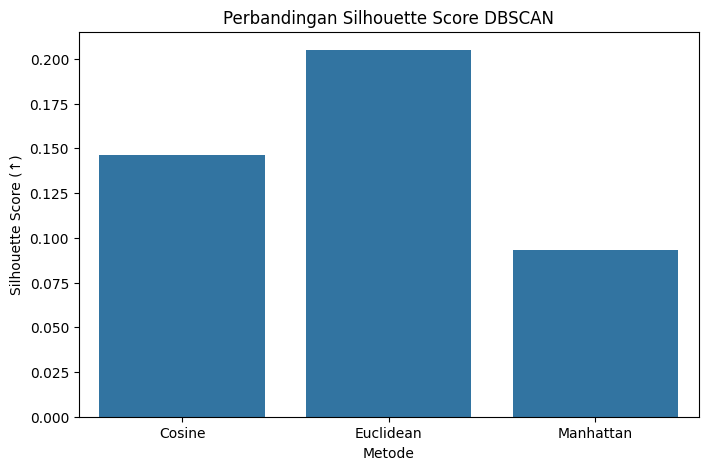

In [4]:
plt.figure(figsize=(8,5))
sns.barplot(data=hasil, x="Metode", y="Silhouette Score (↑)")
plt.title("Perbandingan Silhouette Score DBSCAN")
plt.show()

## 2.2 Perbandingan Davies-Bouldin Index

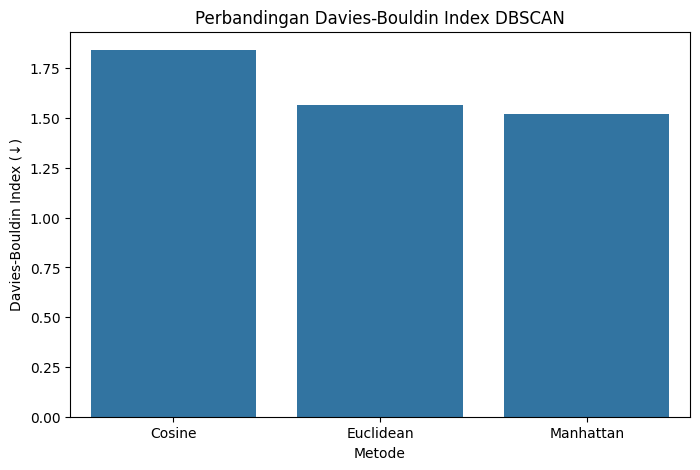

In [5]:
plt.figure(figsize=(8,5))
sns.barplot(data=hasil, x="Metode", y="Davies-Bouldin Index (↓)")
plt.title("Perbandingan Davies-Bouldin Index DBSCAN")
plt.show()

## 2.3 Perbandingan Calinski-Harabasz Index

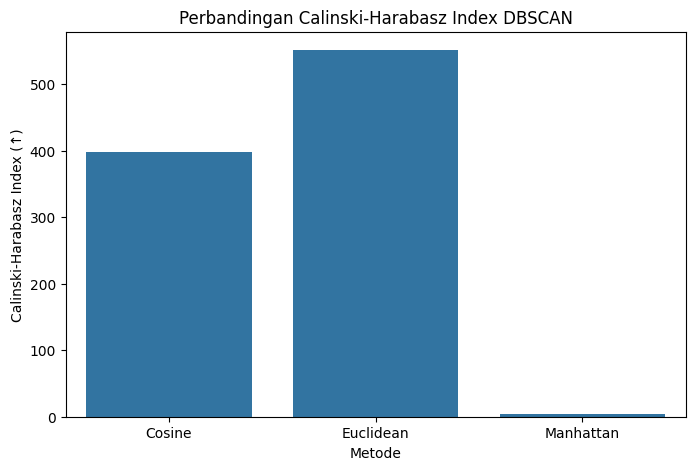

In [6]:
plt.figure(figsize=(8,5))
sns.barplot(data=hasil, x="Metode", y="Calinski-Harabasz Index (↑)")
plt.title("Perbandingan Calinski-Harabasz Index DBSCAN")
plt.show()

## 3. Perbandingan Karakteristik Cluster

Melihat:
- jumlah cluster yang terbentuk
- jumlah data noise
- persentase noise


In [7]:
hasil[['Metode',
       'Jumlah Cluster',
       'Jumlah Noise',
       'Noise (%)']]

,Metode,Jumlah Cluster,Jumlah Noise,Noise (%)
0,Cosine,4,1114,22.28
1,Euclidean,2,834,16.68
2,Manhattan,2,297,5.94


## 4. Ranking Model DBSCAN

In [8]:
ranking = hasil.copy()

ranking["Peringkat Silhouette"] = ranking["Silhouette Score (↑)"].rank(ascending=False)
ranking["Peringkat DB"] = ranking["Davies-Bouldin Index (↓)"].rank(ascending=True)
ranking["Peringkat CH"] = ranking["Calinski-Harabasz Index (↑)"].rank(ascending=False)
ranking["Peringkat Noise"] = ranking["Noise (%)"].rank(ascending=True)

ranking["Total Peringkat"] = (
    ranking["Peringkat Silhouette"]
    + ranking["Peringkat DB"]
    + ranking["Peringkat CH"]
    + ranking["Peringkat Noise"]
)

ranking = ranking.sort_values("Total Peringkat")
ranking


,Model,Distance Metric,eps,min_samples,Jumlah Cluster,Jumlah Noise,Noise (%),Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑),Execution Time (s) (↓),Alokasi Memori (MB),Metode,Peringkat Silhouette,Peringkat DB,Peringkat CH,Peringkat Noise,Total Peringkat
1,DBSCAN Euclidean,Euclidean Distance (L2),4.5280,10,2,834,16.68,0.2049,1.5677,551.37,0.16069,3.25,Euclidean,1.0,2.0,1.0,2.0,6.0
2,DBSCAN Manhattan,Manhattan Distance (L1),16.9631,10,2,297,5.94,0.0931,1.5228,4.26,0.53976,3.45,Manhattan,3.0,1.0,3.0,1.0,8.0
0,DBSCAN Cosine,Cosine Distance,0.3869,10,4,1114,22.28,0.1461,1.8416,398.42,0.54642,383.84,Cosine,2.0,3.0,2.0,3.0,10.0


## 5. Kesimpulan Perbandingan

Model terbaik ditentukan berdasarkan peringkat gabungan dari Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index, dan persentase noise. Setiap metrik diberikan peringkat sesuai arah optimalnya, kemudian peringkat dijumlahkan. Model dengan total peringkat terendah dipilih sebagai model terbaik.


In [9]:
hasil.to_excel("hasil_perbandingan_DBSCAN.xlsx", index=False)
print("File hasil perbandingan berhasil dibuat")


File hasil perbandingan berhasil dibuat
